In [4]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np

# Add RiskLens project root to Python's import path
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

TARGET_COL = "SeriousDlqin2yrs"

from src.config import RANDOM_SEED

print("Imports successful!")
print("Project root:", PROJECT_ROOT)

Imports successful!
Project root: c:\Users\HP\RiskLens


In [6]:
test = pd.read_csv("../data/test.csv", index_col=0)

print("Test shape:", test.shape)

print("\nAvailable columns:")
print(test.columns.tolist())

print("\nFirst five rows:")
display(test.head())

print("\nMissing values:")
print(test.isnull().sum())

Test shape: (30000, 10)

Available columns:
['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']

First five rows:


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
SeriousDlqin2yrs,,,,,,,,,,
0,0.019252,66,0,0.433926,5175.0,13,0,1,0,0.0
0,0.454221,78,0,0.873533,2300.0,7,0,1,0,2.0
0,0.077572,59,0,0.172882,10833.0,5,0,1,0,0.0
0,0.107864,59,0,0.453692,9900.0,10,0,2,0,0.0
0,0.101095,67,0,0.407831,5950.0,14,0,2,0,0.0



Missing values:
RevolvingUtilizationOfUnsecuredLines       0
age                                        0
NumberOfTime30-59DaysPastDueNotWorse       0
DebtRatio                                  0
MonthlyIncome                           6056
NumberOfOpenCreditLinesAndLoans            0
NumberOfTimes90DaysLate                    0
NumberRealEstateLoansOrLines               0
NumberOfTime60-89DaysPastDueNotWorse       0
NumberOfDependents                       796
dtype: int64


In [8]:
test = pd.read_csv("../data/test.csv")

y_test = test[TARGET_COL]
X_test = test.drop(columns=[TARGET_COL])

print("Test dataset shape:", test.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTarget distribution:")
print(y_test.value_counts())

print("\nDefault rate:", y_test.mean())

Test dataset shape: (30000, 11)
X_test shape: (30000, 10)
y_test shape: (30000,)

Target distribution:
SeriousDlqin2yrs
0    27995
1     2005
Name: count, dtype: int64

Default rate: 0.06683333333333333


In [11]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np

from xgboost import XGBClassifier
from sklearn.calibration import CalibratedClassifierCV

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import RANDOM_SEED, TARGET_COL
from src.preprocessing import make_pipeline

print("Imports successful!")

Imports successful!


In [12]:
dev = pd.read_csv("../data/dev.csv")

y_dev = dev[TARGET_COL]
X_dev = dev.drop(columns=[TARGET_COL])

print("Development dataset:", X_dev.shape)
print("Target:", y_dev.shape)

Development dataset: (120000, 10)
Target: (120000,)


In [13]:
spw = (y_dev == 0).sum() / (y_dev == 1).sum()

print("Scale positive weight:", spw)

Scale positive weight: 13.960728088766986


In [14]:
xgb_pipe = make_pipeline(
    XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=1.0,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=spw,
        random_state=RANDOM_SEED,
        n_jobs=-1
    ),
    scale=False
)

print("Tuned XGBoost pipeline created!")

Tuned XGBoost pipeline created!


In [15]:
final_pipe = CalibratedClassifierCV(
    estimator=xgb_pipe,
    method="isotonic",
    cv=5
)

print("Final calibrated model created!")

Final calibrated model created!


In [16]:
final_pipe.fit(X_dev, y_dev)

y_prob_test = final_pipe.predict_proba(X_test)[:, 1]

print("Final model fitted successfully!")
print("Test predictions generated:", len(y_prob_test))

Final model fitted successfully!
Test predictions generated: 30000


In [17]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

final_metrics = {
    "ROC-AUC": roc_auc_score(y_test, y_prob_test),
    "PR-AUC": average_precision_score(y_test, y_prob_test),
    "Brier Score": brier_score_loss(y_test, y_prob_test)
}

print("FINAL TEST RESULTS")
print("-" * 35)

for metric, value in final_metrics.items():
    print(f"{metric}: {value:.6f}")

FINAL TEST RESULTS
-----------------------------------
ROC-AUC: 0.869142
PR-AUC: 0.404330
Brier Score: 0.048683


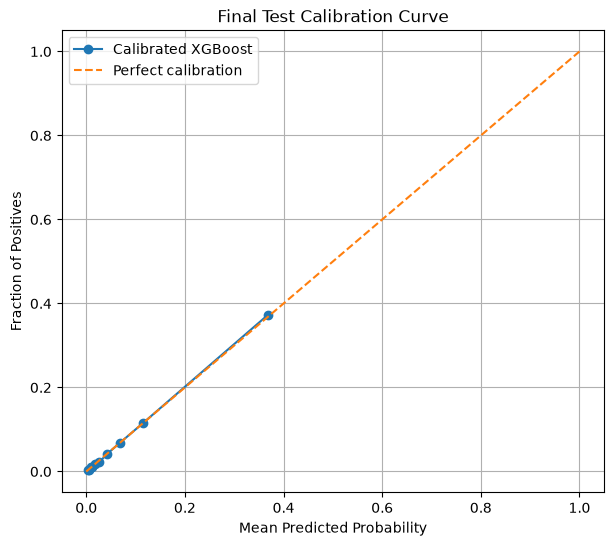

In [18]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

fraction_positive, mean_predicted = calibration_curve(
    y_test,
    y_prob_test,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Calibrated XGBoost"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Final Test Calibration Curve")
plt.legend()
plt.grid(True)

plt.savefig("../figures/final_test_calibration.png", dpi=300)
plt.show()

In [19]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

final_threshold = 0.23

y_pred_test = (y_prob_test >= final_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred_test
).ravel()

print("FINAL TEST CLASSIFICATION RESULTS")
print("---------------------------------")
print("Threshold:", final_threshold)
print("Precision:", precision_score(y_test, y_pred_test))
print("Recall:", recall_score(y_test, y_pred_test))
print("F1-score:", f1_score(y_test, y_pred_test))

print("\nConfusion Matrix")
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

FINAL TEST CLASSIFICATION RESULTS
---------------------------------
Threshold: 0.23
Precision: 0.40325865580448067
Recall: 0.4937655860349127
F1-score: 0.4439461883408072

Confusion Matrix
TN: 26530
FP: 1465
FN: 1015
TP: 990


### Step 10.6 — Test vs Development CV Comparison

The final test ROC-AUC (0.869142) and PR-AUC (0.404330) are slightly higher than the development cross-validation ROC-AUC (0.864819) and PR-AUC (0.400979).

This indicates that the model's ranking performance is consistent between development and test data, with no obvious evidence of a substantial performance drop.

The Brier scores require a separate comparison because the development values shown above are for the uncalibrated tuned XGBoost model, whereas the final test evaluation uses calibrated XGBoost.

No further model tuning will be performed using the locked test set.


### Step 10.7 — Final Test Checkpoint

* [x] Test set evaluated once using the final calibrated model.
* [x] Final test metrics recorded.
* [x] Final test calibration curve generated.
* [x] Confusion matrix evaluated at the development-selected threshold of 0.23.
* [x] No further test-driven model changes will be made.

Final test metrics are preserved for reporting in `results/final_test_metrics.json`.


In [20]:
import json
from pathlib import Path

final_test_metrics = {
    "roc_auc": 0.869142,
    "pr_auc": 0.404330,
    "brier_score": 0.048683,
    "threshold": 0.23,
    "precision": 0.40325865580448067,
    "recall": 0.4937655860349127,
    "f1_score": 0.4439461883408072,
    "tn": 26530,
    "fp": 1465,
    "fn": 1015,
    "tp": 990
}

output_path = Path("../results/final_test_metrics.json")
output_path.parent.mkdir(parents=True, exist_ok=True)

with open(output_path, "w") as f:
    json.dump(final_test_metrics, f, indent=4)

print("Final test metrics saved successfully!")
print(output_path.resolve())

Final test metrics saved successfully!
C:\Users\HP\RiskLens\results\final_test_metrics.json


In [21]:
with open("../results/final_test_metrics.json", "r") as f:
    saved_metrics = json.load(f)

print(json.dumps(saved_metrics, indent=4))

{
    "roc_auc": 0.869142,
    "pr_auc": 0.40433,
    "brier_score": 0.048683,
    "threshold": 0.23,
    "precision": 0.40325865580448067,
    "recall": 0.4937655860349127,
    "f1_score": 0.4439461883408072,
    "tn": 26530,
    "fp": 1465,
    "fn": 1015,
    "tp": 990
}


In [22]:
import pandas as pd

threshold = 0.23

test_predictions = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "probability": y_prob_test,
    "predicted": (y_prob_test >= threshold).astype(int)
})

test_predictions["error_type"] = "Correct"

test_predictions.loc[
    (test_predictions["actual"] == 1) &
    (test_predictions["predicted"] == 0),
    "error_type"
] = "False Negative"

test_predictions.loc[
    (test_predictions["actual"] == 0) &
    (test_predictions["predicted"] == 1),
    "error_type"
] = "False Positive"

test_predictions.to_csv(
    "../results/test_error_analysis.csv",
    index=False
)

print(test_predictions["error_type"].value_counts())
print("Predictions saved successfully!")

error_type
Correct           27520
False Positive     1465
False Negative     1015
Name: count, dtype: int64
Predictions saved successfully!
